# Data processing and Model 1

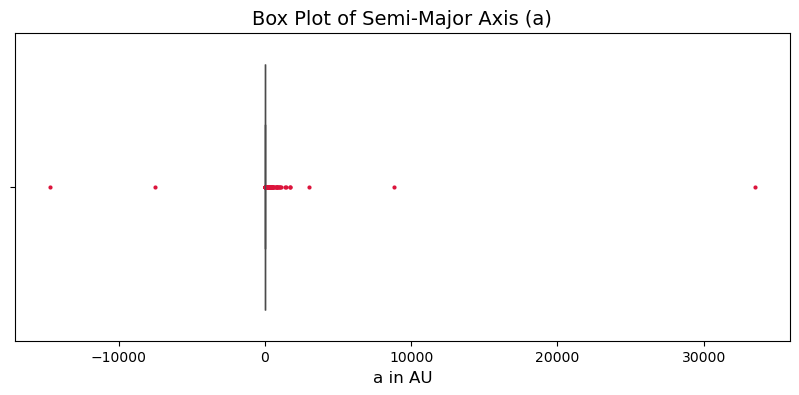

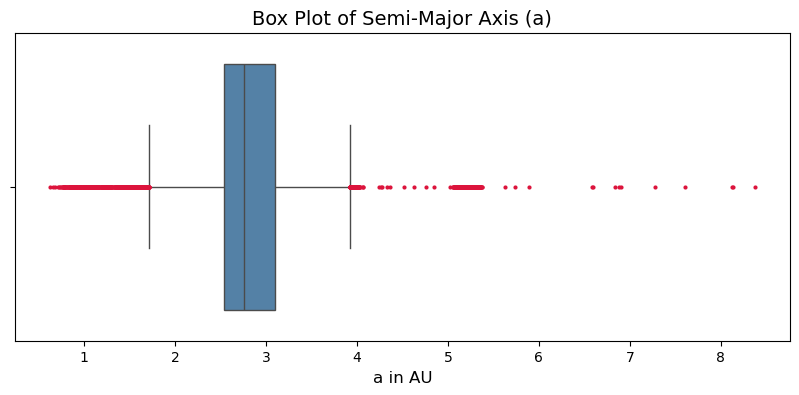

In [ ]:
#Load the data and remove the qualitative information 
import pandas as pd
from sklearn.preprocessing import StandardScaler
import seaborn as sns

file_path = '/Users/lilly-anne/Desktop/Portfolio/dataset.csv'
df = pd.read_csv(file_path, low_memory=False)
df_clean = df[['a', 'i', 'q', 'e', 'moid_ld', 'diameter', 'albedo', 'epoch', 'tp']].dropna() #To make sure not NaN


#I was getting weird results in my training and testing. I looked into it with sources mentioned above and AI (mostly to correct produced code) to remove outliers and see if improved- it did
#AI help make pretty boxlpots
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(
    x=df['a'], 
    ax=ax, 
    color='steelblue', 
    flierprops={'markerfacecolor': 'crimson', 'markeredgecolor': 'none', 'markersize': 3}
)
ax.set_title('Box Plot of Semi-Major Axis (a)', fontsize=14)
ax.set_xlabel('a in AU', fontsize=12)


#From the first box plot I saw that there were many many outliers and that the spread was quite large. Therefore I plotted with a smaller range o get a closer look
fig, ax = plt.subplots(figsize=(10, 4))
df_view = df_clean[(df_clean['a'] > 0) & (df_clean['a'] < 10)] 

#plot made pretty with AI
sns.boxplot(
    x= df_view['a'],
    ax=ax, 
    color='steelblue', 
    flierprops={'markerfacecolor': 'crimson', 'markeredgecolor': 'none', 'markersize': 3}
)

ax.set_title('Box Plot of Semi-Major Axis (a)', fontsize=14)
ax.set_xlabel('a in AU', fontsize=12)
plt.show()


In [ ]:
#Use within 3 standard deviations, the z score method. This seemed better and more consistant than doing it visually 
mean_a=df_clean['a'].mean()
std_a=df_clean['a'].std()

lower = mean_a - (3 * std_a)
upper= mean_a + (3 * std_a)

df_clean=df_clean[(df_clean['a'] >= lower) & (df_clean['a'] <= upper)].copy()

In [ ]:
class CustomDataset(Dataset):
    def __init__(self, data, labels):
        self.data = data
        self.labels = labels

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        data_idx = self.data[idx]
        label = self.labels[idx].float() #Change this because the torch.long tensor is for integers
        return data_idx, label


In [ ]:
#Here we prepare the data. There is definitely a more efficient way to do this. However, I struggled quite a bit and this made it easier to see and understand what was going on.
#AI was used here to make sure the dimensions and data types were correct - many many errors made here in this section. That is also the reason why I load data for each section again. It makes it easier for me to see and understand what I'm working with
#A lot of it is repetetive (the same step for each of the feature. I gave AI the format I wanted and asked it to generate the code for the features to save time and errors)


#shuffle and split the data
df_shuffled = df_clean.sample(frac=1, random_state=42).reset_index(drop=True) #USed AI to get the best way to shuffle data
halfway = int(len(df_shuffled) / 2)

#Split the data
training = df_shuffled.iloc[:halfway].copy()
testing = df_shuffled.iloc[halfway:].copy()

#Here we normalize the data, without normalization the test and train losses look a bit weird. It also makes it difficult to compare the different features because of the different units.
feature_cols = ['i', 'q', 'e', 'moid_ld', 'diameter', 'albedo', 'epoch', 'tp']
scaler_X = StandardScaler()
scaler_y = StandardScaler()

training[feature_cols] = scaler_X.fit_transform(training[feature_cols])  
testing[feature_cols]  = scaler_X.transform(testing[feature_cols])    
training[['a']] = scaler_y.fit_transform(training[['a']])
testing[['a']]  = scaler_y.transform(testing[['a']])

# Tensors for the labels
training_label_torch = torch.Tensor(training['a'].to_numpy()).unsqueeze(1)
testing_label_torch  = torch.Tensor(testing['a'].to_numpy()).unsqueeze(1)

#Tensors for the features
training_i_torch = torch.Tensor(training['i'].to_numpy()).unsqueeze(1)
testing_i_torch  = torch.Tensor(testing['i'].to_numpy()).unsqueeze(1)

training_e_torch = torch.Tensor(training['e'].to_numpy()).unsqueeze(1)
testing_e_torch  = torch.Tensor(testing['e'].to_numpy()).unsqueeze(1)

training_moid_torch = torch.Tensor(training['moid_ld'].to_numpy()).unsqueeze(1)
testing_moid_torch  = torch.Tensor(testing['moid_ld'].to_numpy()).unsqueeze(1)

training_diam_torch = torch.Tensor(training['diameter'].to_numpy()).unsqueeze(1)
testing_diam_torch  = torch.Tensor(testing['diameter'].to_numpy()).unsqueeze(1)

training_albedo_torch = torch.Tensor(training['albedo'].to_numpy()).unsqueeze(1)
testing_albedo_torch  = torch.Tensor(testing['albedo'].to_numpy()).unsqueeze(1)

training_epoch_torch = torch.Tensor(training['epoch'].to_numpy()).unsqueeze(1)
testing_epoch_torch  = torch.Tensor(testing['epoch'].to_numpy()).unsqueeze(1)

training_q_torch = torch.Tensor(training['q'].to_numpy()).unsqueeze(1)
testing_q_torch  = torch.Tensor(testing['q'].to_numpy()).unsqueeze(1)

training_tp_torch = torch.Tensor(training['tp'].to_numpy()).unsqueeze(1)
testing_tp_torch  = torch.Tensor(testing['tp'].to_numpy()).unsqueeze(1)


# Make object of the dataset class
train_dataset_class_i = CustomDataset(training_i_torch, training_label_torch)
test_dataset_class_i = CustomDataset(testing_i_torch,testing_label_torch)

train_dataset_class_e = CustomDataset(training_e_torch,training_label_torch)
test_dataset_class_e = CustomDataset(testing_e_torch,testing_label_torch)

train_dataset_class_moid = CustomDataset(training_moid_torch,training_label_torch)
test_dataset_class_moid = CustomDataset(testing_moid_torch,testing_label_torch)

train_dataset_class_diam = CustomDataset(training_diam_torch,training_label_torch)
test_dataset_class_diam = CustomDataset(testing_diam_torch,testing_label_torch)


train_dataset_class_albedo = CustomDataset(training_albedo_torch, training_label_torch)
test_dataset_class_albedo = CustomDataset(testing_albedo_torch,testing_label_torch)
train_dataset_class_epoch = CustomDataset(training_epoch_torch, training_label_torch)
test_dataset_class_epoch = CustomDataset(testing_epoch_torch,testing_label_torch)
train_dataset_class_q = CustomDataset(training_q_torch,training_label_torch)
test_dataset_class_q = CustomDataset(testing_q_torch,testing_label_torch)
train_dataset_class_tp = CustomDataset(training_tp_torch,training_label_torch)
test_dataset_class_tp = CustomDataset(testing_tp_torch,testing_label_torch)


# Batch it 
batch_size = 8192 # Tried different batch sizes, but lower values took forever to run
train_dataloader_i= DataLoader(train_dataset_class_i,batch_size=batch_size)
test_dataloader_i = DataLoader(test_dataset_class_i,batch_size=batch_size)
train_dataloader_e= DataLoader(train_dataset_class_e,batch_size=batch_size)
test_dataloader_e= DataLoader(test_dataset_class_e,batch_size=batch_size)
train_dataloader_moid = DataLoader(train_dataset_class_moid,batch_size=batch_size)
test_dataloader_moid = DataLoader(test_dataset_class_moid,batch_size=batch_size)
train_dataloader_diam = DataLoader(train_dataset_class_diam,batch_size=batch_size)
test_dataloader_diam = DataLoader(test_dataset_class_diam,batch_size=batch_size)

# New DataLoaders
train_dataloader_albedo = DataLoader(train_dataset_class_albedo,batch_size=batch_size)
test_dataloader_albedo= DataLoader(test_dataset_class_albedo,batch_size=batch_size)
train_dataloader_epoch = DataLoader(train_dataset_class_epoch,batch_size=batch_size)
test_dataloader_epoch= DataLoader(test_dataset_class_epoch,batch_size=batch_size)
train_dataloader_q = DataLoader(train_dataset_class_q,batch_size=batch_size)
test_dataloader_q= DataLoader(test_dataset_class_q,batch_size=batch_size)
train_dataloader_tp= DataLoader(train_dataset_class_tp,batch_size=batch_size)
test_dataloader_tp = DataLoader(test_dataset_class_tp,batch_size=batch_size)


all_data_set_train = [train_dataloader_i, train_dataloader_e, train_dataloader_moid, train_dataloader_diam,train_dataloader_albedo, train_dataloader_epoch, train_dataloader_q, train_dataloader_tp]
all_data_sets_test = [test_dataloader_i,  test_dataloader_e,  test_dataloader_moid,  test_dataloader_diam,test_dataloader_albedo, test_dataloader_epoch, test_dataloader_q, test_dataloader_tp]



Loss from inputs: Inclination = 0.9352105723487006
R^2 = 0.05568415694195927 for inputs: Inclination

Loss from inputs: Eccentricity = 0.9491261972321404
R^2 = 0.042341488601863264 for inputs: Eccentricity

Loss from inputs: Earth Minimum Orbit = 0.17106279730796814
R^2 = 0.8278618616725092 for inputs: Earth Minimum Orbit

Loss from inputs: Object diameter = 0.6671351922882928
R^2 = 0.32563686756957755 for inputs: Object diameter

Loss from inputs: Albedo = 0.8528913590643141
R^2 = 0.13965002646396418 for inputs: Albedo

Loss from inputs: Epoch = 0.980493426322937
R^2 = 0.012063334805159198 for inputs: Epoch

Loss from inputs: Perihelion = 0.17719777756267124
R^2 = 0.8219881403933837 for inputs: Perihelion

Loss from inputs: Time of perihelion passage = 0.8230820430649651
R^2 = 0.1722931654188402 for inputs: Time of perihelion passage



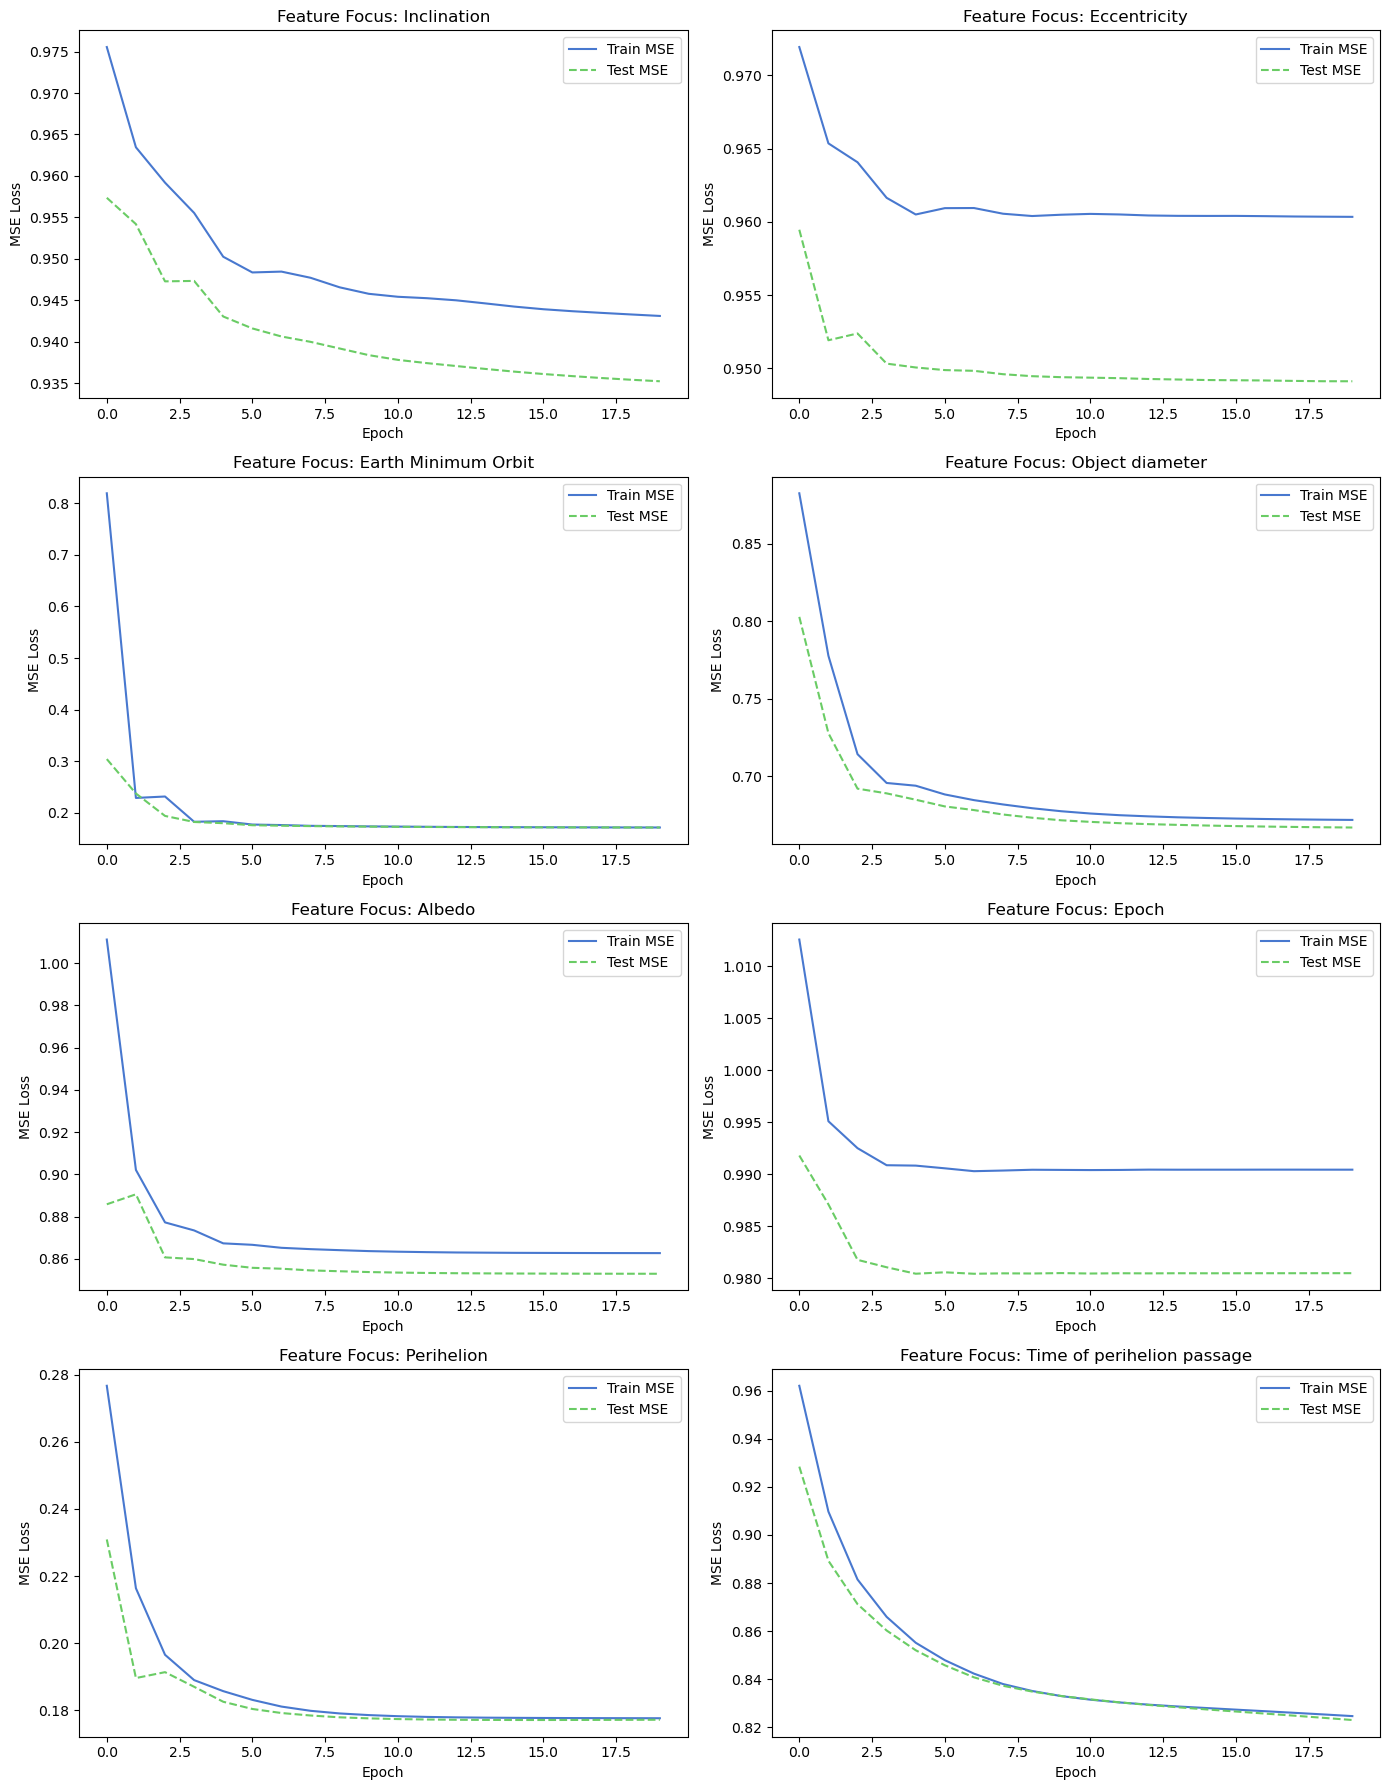

In [ ]:
#Model 1 testing which parameters work best and how many
#neural network with 1 hidden layer 
class NeuralNetwork_1(nn.Module):
    def __init__(self, num_input, num_neuron):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(num_input, num_neuron),
            nn.ReLU(),
            nn.Linear(num_neuron, 1),
        )
        
    def forward(self, x):
        logits = self.linear_relu_stack(x)
        return logits
    

#Regression model instead of categorizing, so make some adjustments
def train(dataloader, model, loss_fn, optimizer, train_loss):
    num_batches = len(dataloader)
    size = len(dataloader.dataset)
    model.train()
    running_loss = 0

    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        if batch % 25 == 0:
            loss, current = loss.item(), batch * len(X)

    running_loss /= num_batches
    train_loss.append(running_loss)

def test(dataloader, model, loss_fn, test_loss):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    running_loss = 0

    pred_running = []
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            running_loss += loss_fn(pred, y).item()
            pred_running.append(pred)
    running_loss /= num_batches
    test_loss.append(running_loss)
    pred_running = torch.cat(pred_running).numpy().ravel()
    return pred_running

epochs = 20 #10 epochs because 50 runs for 15+ minutes. 10 epochs takes 3 minutes
learn_rate = 0.01

end_loss_model1 = []  #To get the final losses for each feature
end_r2 = [] #To get the r2 value for each feature

model_name = ['Inclination', 'Eccentricity', 'Earth Minimum Orbit', 'Object diameter','Albedo', 'Epoch', 'Perihelion', 'Time of perihelion passage']

fig, axes = plt.subplots(4, 2, figsize=(14, 18)) 
axes_flat = axes.flatten()

for i in range(len(all_data_sets_test)):
    model = NeuralNetwork_1(1,32).to(device)
    loss_fn = nn.MSELoss()  #This one adjusted for regression, got erros AI helped. Quick google search also gives this as best option
    optimizer = torch.optim.Adam(model.parameters(), learn_rate)
    train_loss_dnn = []
    test_loss_dnn = []
    for t in range(epochs):
        train(all_data_set_train[i], model, loss_fn, optimizer, train_loss_dnn)
        preds = test(all_data_sets_test[i], model, loss_fn, test_loss_dnn)
    
    #Pretty plots with AI
    ax = axes_flat[i]
    ax.plot(train_loss_dnn, label='Train MSE')
    ax.plot(test_loss_dnn,  label='Test MSE',linestyle='--')
    
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE Loss')
    ax.set_title(f'Feature Focus: {model_name[i]}')
    ax.legend()
    
    end_loss_model1.append(test_loss_dnn[-1])
    print(f'Loss from inputs: {model_name[i]} = {test_loss_dnn[-1]}')

    trues = testing['a'].to_numpy()
    r2_model1 = 1 - np.sum((preds - trues)**2) / np.sum((trues - trues.mean())**2)
    end_r2.append(r2_model1 )
    print(f'R^2 = {r2_model1} for inputs: {model_name[i]}\n')

plt.tight_layout()
plt.show()

#I looked at the best performing feature and I will use this at the end for the final comparison
loss_model1 = end_loss_model1[2]
r2_model1 = end_r2[2]

# Model 2 Multiple Inputs
## From above we see that the best parameters are: perihelion, earth orbit and diameter we look at combinations in this section of these features to determine the best inputs


In [ ]:
#When preparing the data, I;ve copy and pasted from what I did for model one. This is because data points if there was a NaN in any parameter. Now that we're working with just a few parameters we want to keep the rows that were removed due to NaN for other features
#Same AI usage as previous

file_path = '/Users/lilly-anne/Desktop/ap3751-2026-kalderen/dataset.csv'
df2 = pd.read_csv(file_path, low_memory=False)
df_clean = df[['a', 'q', 'moid_ld', 'diameter']].dropna() #To make sure not NaN

mean_a= df_clean['a'].mean()
std_a= df_clean['a'].std()

lower = mean_a - (3 * std_a)
upper= mean_a + (3 * std_a)

df_clean = df_clean[(df_clean['a'] >= lower) & (df_clean['a'] <= upper)].copy()

df_shuffled = df_clean.sample(frac=1, random_state=42).reset_index(drop=True)
halfway = int(len(df_shuffled) / 2)

#Training and testing label
training = df_shuffled.iloc[:halfway].copy()
testing = df_shuffled.iloc[halfway:].copy()

#Prepare feature data as we did above in model 1

#Normalzie
feature_cols = ['q', 'moid_ld', 'diameter']
scaler_X = StandardScaler()
scaler_y = StandardScaler()

training[feature_cols] = scaler_X.fit_transform(training[feature_cols]) 
testing[feature_cols] = scaler_X.transform(testing[feature_cols])      
training[['a']] = scaler_y.fit_transform(training[['a']])
testing[['a']] = scaler_y.transform(testing[['a']])

#Training and testing 
training_label_torch = torch.Tensor(training['a'].to_numpy()).unsqueeze(1)
testing_label_torch = torch.Tensor(testing['a'].to_numpy()).unsqueeze(1)

training_moid_torch = torch.Tensor(training['moid_ld'].to_numpy()).unsqueeze(1)
testing_moid_torch = torch.Tensor(testing['moid_ld'].to_numpy()).unsqueeze(1)

training_diam_torch = torch.Tensor(training['diameter'].to_numpy()).unsqueeze(1)
testing_diam_torch = torch.Tensor(testing['diameter'].to_numpy()).unsqueeze(1)

training_q_torch= torch.Tensor(training['q'].to_numpy()).unsqueeze(1)
testing_q_torch = torch.Tensor(testing['q'].to_numpy()).unsqueeze(1)

# combine the different combinations for different input possibilities
combo_all_train = torch.cat([training_q_torch, training_moid_torch, training_diam_torch], dim=1)
combo_q_moid_train = torch.cat([training_q_torch, training_moid_torch],dim=1)
combo_q_diam_train= torch.cat([training_q_torch, training_diam_torch],dim=1)
combo_diam_moid_train = torch.cat([training_moid_torch, training_diam_torch],dim=1)

combo_all_test= torch.cat([testing_q_torch, testing_moid_torch, testing_diam_torch],dim=1)
combo_q_moid_test = torch.cat([testing_q_torch, testing_moid_torch],dim=1)
combo_q_diam_test= torch.cat([testing_q_torch, testing_diam_torch],dim=1)
combo_diam_moid_test = torch.cat([testing_moid_torch, testing_diam_torch],dim=1)


#Run through customdataset
train_dataset_class_all= CustomDataset(combo_all_train,training_label_torch)
test_dataset_class_all= CustomDataset(combo_all_test,testing_label_torch)

train_dataset_class_q_moid= CustomDataset(combo_q_moid_train,training_label_torch)
test_dataset_class_q_moid = CustomDataset(combo_q_moid_test,testing_label_torch)

train_dataset_class_q_diam = CustomDataset(combo_q_diam_train,training_label_torch)
test_dataset_class_q_diam= CustomDataset(combo_q_diam_test,testing_label_torch)

train_dataset_class_diam_moid = CustomDataset(combo_diam_moid_train,training_label_torch)
test_dataset_class_diam_moid = CustomDataset(combo_diam_moid_test,testing_label_torch)

#Batch
batch_size = 8192
train_dataloader_all = DataLoader(train_dataset_class_all,batch_size=batch_size)
test_dataloader_all = DataLoader(test_dataset_class_all,batch_size=batch_size)

train_dataloader_q_moid = DataLoader(train_dataset_class_q_moid,batch_size=batch_size)
test_dataloader_q_moid = DataLoader(test_dataset_class_q_moid,batch_size=batch_size)

train_dataloader_q_diam = DataLoader(train_dataset_class_q_diam,batch_size=batch_size)
test_dataloader_q_diam = DataLoader(test_dataset_class_q_diam,batch_size=batch_size)

train_dataloader_diam_moid = DataLoader(train_dataset_class_diam_moid,batch_size=batch_size)
test_dataloader_diam_moid = DataLoader(test_dataset_class_diam_moid,batch_size=batch_size)

#Names and labels for when we plot 
train_loop  = [train_dataloader_all, train_dataloader_q_moid, train_dataloader_q_diam, train_dataloader_diam_moid]
test_loop   = [test_dataloader_all,  test_dataloader_q_moid,  test_dataloader_q_diam,  test_dataloader_diam_moid]
num_inputs  = [3, 2, 2, 2]
name_inputs = ['q + moid + diam', 'q + moid', 'q + diam', 'moid + diam']


Loss from inputs: Earth Minimum Orbit, Object diameter and Perihelion = 0.16128615041573843
R^2 = 0.8390156163123077 for inputs: Inclination
Loss from inputs: Earth Minimum Orbit and Perihelion = 0.17112722661760119
R^2 = 0.8292753449516963 for inputs: Eccentricity
Loss from inputs: Earth Minimum Orbit and Perihelion = 0.1676572577820884
R^2 = 0.8326901269049509 for inputs: Earth Minimum Orbit
Loss from inputs: Earth Minimum Orbit and Object diameter = 0.16337688267230988
R^2 = 0.8369508637913609 for inputs: Object diameter


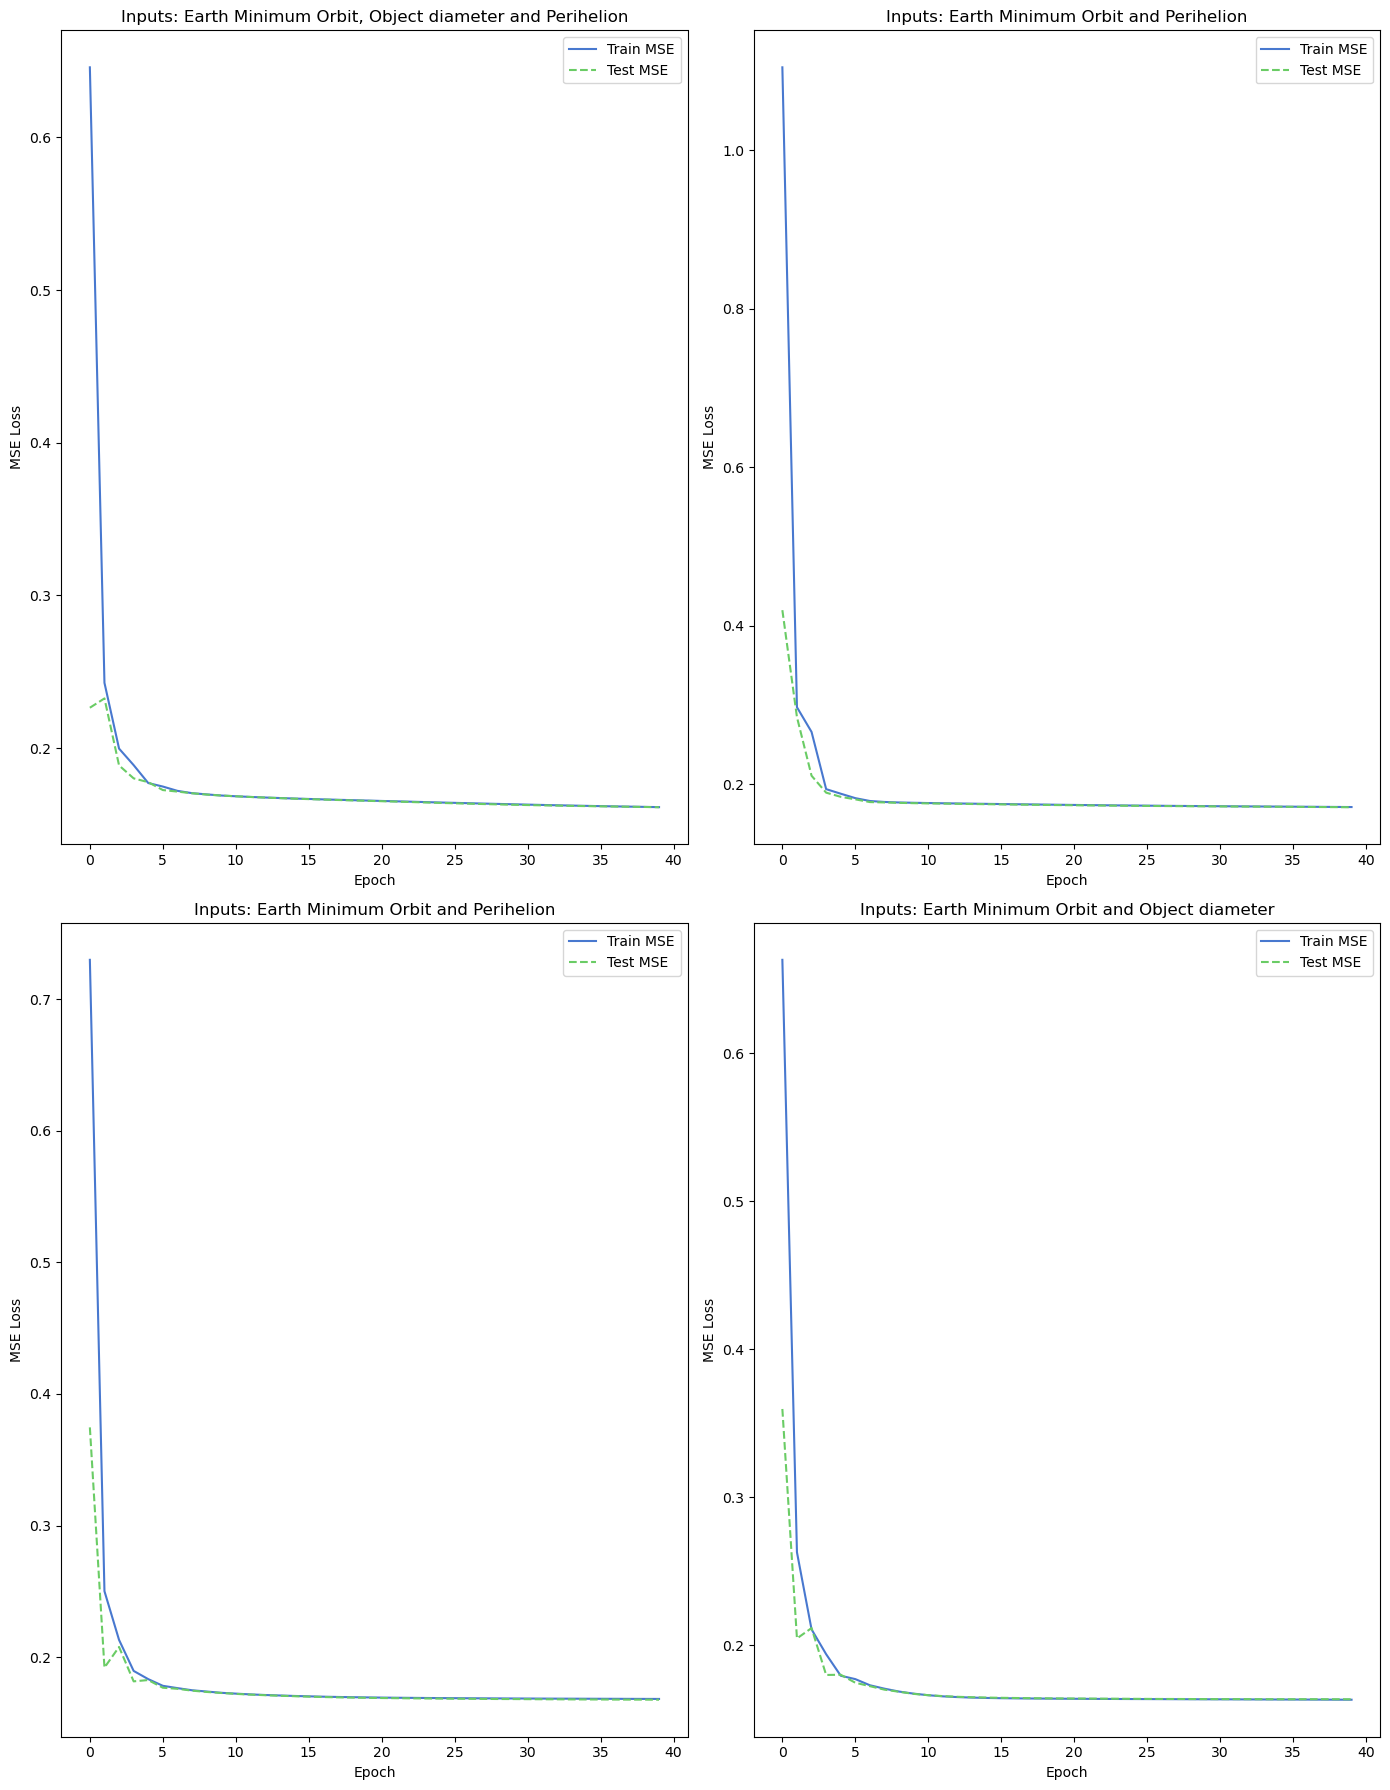

In [ ]:
#Copy code fomr model 1, change the number of inputs and the inputs
epochs = 40 #10 epochs because 50 runs for 15+ minutes. 10 epochs takes 3 minutes
learn_rate = 0.01
end_loss_model2 = []

name_inputs = ['Earth Minimum Orbit, Object diameter and Perihelion', 'Earth Minimum Orbit and Perihelion', 'Earth Minimum Orbit and Perihelion','Earth Minimum Orbit and Object diameter']
fig, axes = plt.subplots(2, 2, figsize=(14, 18)) 
axes_flat = axes.flatten()


for i in range(len(test_loop)):
    model = NeuralNetwork_1(num_inputs[i],32).to(device)
    loss_fn = nn.MSELoss()  
    optimizer = torch.optim.Adam(model.parameters(), learn_rate)
    train_loss_dnn = []
    test_loss_dnn = []
    for t in range(epochs):
        train(train_loop[i], model, loss_fn, optimizer, train_loss_dnn)
        preds = test(test_loop[i], model, loss_fn, test_loss_dnn)

    #Pretty plots wiwth AI
    ax = axes_flat[i]
    ax.plot(train_loss_dnn, label='Train MSE')
    ax.plot(test_loss_dnn,  label='Test MSE',linestyle='--')
    
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE Loss')
    ax.set_title(f'Inputs: {name_inputs[i]}')
    ax.legend()

    #Print the lost off each
    end_loss_model2.append(test_loss_dnn[-1])
    print(f'Loss from inputs: {name_inputs[i]} = {test_loss_dnn[-1]}')
    loss_model2 = test_loss_dnn[-1]

    #Print the r^2
    trues = testing['a'].to_numpy()
    r2_model2 = 1 - np.sum((preds- trues)**2) / np.sum((trues - trues.mean())**2)
    print(f'R^2 = {r2_model2} for inputs: {model_name[i]}')

plt.tight_layout()
plt.show()

#The optimal inputs are the last in the list so rename the training and testing loss so that we can plot them with model 3 and compare with the rest of the models
train_loss_dnn2 = train_loss_dnn
test_loss_dnn2 = test_loss_dnn




# Model 3 - 2 hidden layers
## In model 2 we see that the accuracys and reliabilites are very similar for the different inputs, the three inputs is slightly better than the best 2 input combination. THat is why I chose to continue with 2 inputs because the difference in accuracy is very small so fine tuning this will probably be more efficient (diameter and minumum orbit)

1 hidden layer loss from inputs: Earth Minimum Orbit and Object diameter = 0.16337688267230988
R^2 = 0.8369508637913609 for inputs Earth Minimum Orbit and Object diameter
2 hidden layer loss from inputs: Earth Minimum Orbit and Object diameter = 0.16075629161463845
R^2 = 0.8395080820400931 for inputs: Object diameter with 2 hidden layers


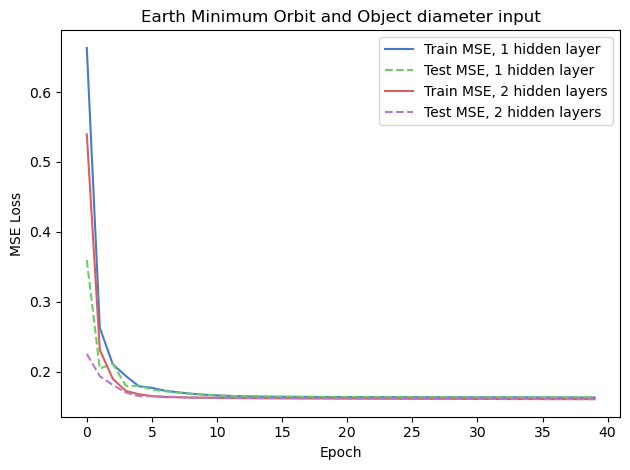

In [ ]:
#Change the number of hidden layers to 2 and compare to the result from above

#plot and print above results
plt.plot(train_loss_dnn2, label='Train MSE, 1 hidden layer')
plt.plot(test_loss_dnn2,  label='Test MSE, 1 hidden layer',linestyle='--')

print(f'1 hidden layer loss from inputs: {name_inputs[i]} = {test_loss_dnn[-1]}')
print(f'R^2 = {r2_model2} for inputs Earth Minimum Orbit and Object diameter')

class NeuralNetwork_2(nn.Module):
    def __init__(self, num_input, num_neuron):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(num_input, num_neuron),
            nn.ReLU(),
            nn.Linear(num_neuron, num_neuron),
            nn.ReLU(),
            nn.Linear(num_neuron, 1),
        )
    def forward(self, x):
        logits = self.linear_relu_stack(x)
        return logits
    
#Determine from model 2 that these were the best
train_model3 = train_dataloader_diam_moid
test_model3 = test_dataloader_diam_moid

epochs = 40 #10 epochs because 50 runs for 15+ minutes. 10 epochs takes 3 minutes
learn_rate = 0.01
end_loss_model3 = []

model = NeuralNetwork_2(2,32).to(device)
loss_fn = nn.MSELoss()  
optimizer = torch.optim.Adam(model.parameters(), learn_rate)

train_loss_dnn = []
test_loss_dnn = []
end_loss_model3 = []

for t in range(epochs):
    train(train_model3, model, loss_fn, optimizer, train_loss_dnn)
    pred = test(test_model3,model, loss_fn, test_loss_dnn)

#Print accuracy
print(f'2 hidden layer loss from inputs: {name_inputs[i]} = {test_loss_dnn[-1]}')
loss_model3 = test_loss_dnn[-1]

#PLots pretty with AI
plt.plot(train_loss_dnn, label='Train MSE, 2 hidden layers')
plt.plot(test_loss_dnn,  label='Test MSE, 2 hidden layers',linestyle='--')  
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title(f'Earth Minimum Orbit and Object diameter input')
plt.legend()

end_loss_model3.append(test_loss_dnn[-1]) #Save this to compare at the end

#Print and save r^2 for comparison at the end
trues = testing['a'].to_numpy()
r2_model3 = 1 - np.sum((pred - trues)**2) / np.sum((trues - trues.mean())**2)
print(f'R^2 = {r2_model3} for inputs: {model_name[i]} with 2 hidden layers')

plt.tight_layout()
plt.show()




# Model 4 CNN

In [ ]:
#Model 4 CNN From notebook 4
import numpy as np

# We will design the network and train it in PyTorch
import torch
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim

# For convenient data loading
from torch.utils.data import Dataset
from torch.utils.data import DataLoader

# To plot progress bars
from tqdm.notebook import trange, tqdm
# To calculate how long the training takes
from datetime import datetime

# For plotting
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()
sns.color_palette("Paired")

#Data is already uploaded



[(0.6509803921568628, 0.807843137254902, 0.8901960784313725),
 (0.12156862745098039, 0.47058823529411764, 0.7058823529411765),
 (0.6980392156862745, 0.8745098039215686, 0.5411764705882353),
 (0.2, 0.6274509803921569, 0.17254901960784313),
 (0.984313725490196, 0.6039215686274509, 0.6),
 (0.8901960784313725, 0.10196078431372549, 0.10980392156862745),
 (0.9921568627450981, 0.7490196078431373, 0.43529411764705883),
 (1.0, 0.4980392156862745, 0.0),
 (0.792156862745098, 0.6980392156862745, 0.8392156862745098),
 (0.41568627450980394, 0.23921568627450981, 0.6039215686274509),
 (1.0, 1.0, 0.6),
 (0.6941176470588235, 0.34901960784313724, 0.1568627450980392)]

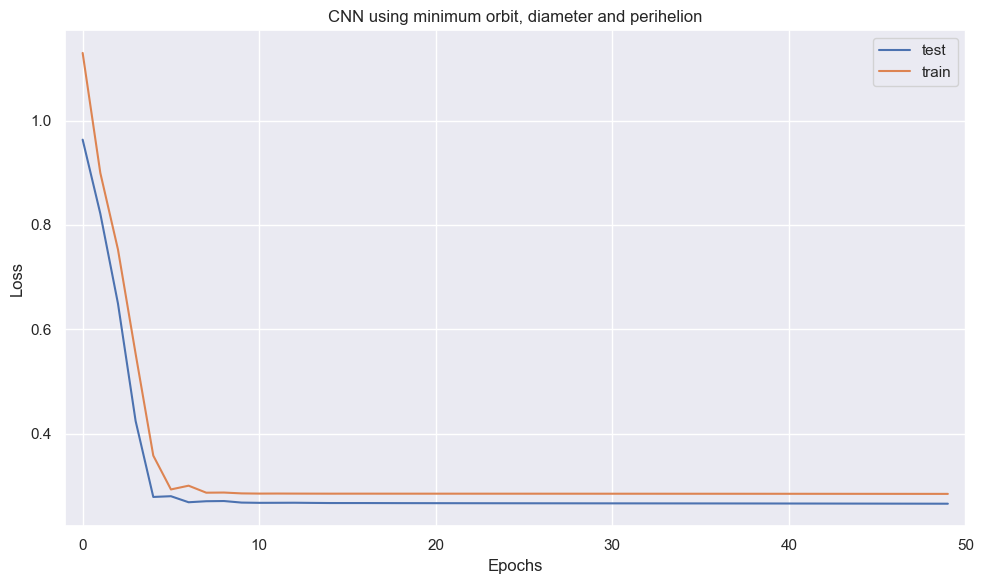

R^2 = 0.8395080820400931 for CNN with minimum orbit, diameter and perihelion
Loss is test_loss_cnn[-1]


In [ ]:
#Copy from notebook TestrisCNN, make adjustments for our situation
#Most things were removed by looking at the pytorch documentation for 1d convolutions. However the unsqueeze squeeze and the linear regression addition were AI help, and I further looked into the nn.linear documentation and function

class conv(nn.Module):
    def __init__(
        self,
        in_channels,
        kernel_shape,
        hidden_size,
        number_of_filters,

    ):
        super().__init__()

        self.input_dim = in_channels
        self.kernel_shape = kernel_shape
        self.hidden_size = hidden_size
        self.number_of_filters = number_of_filters 
        

        self.conv1 = nn.Conv1d(
            in_channels=in_channels,
            kernel_size=self.kernel_shape,
            out_channels=self.hidden_size,
            stride=1,
            padding=1,
  
        )
        self.conv2 = nn.Conv1d(
            in_channels=self.hidden_size,
            out_channels=self.number_of_filters,
            kernel_size=1,
            padding = 1,
            stride=1,

        )
    
        self.regressor = nn.Linear(self.number_of_filters, 1) #This takes the different features we are looking at so the number of filters and then outputs 1 because that's the dimension of our output
        
    def forward(self, x):
        x = x.unsqueeze(1) #So that the shape is correct 
        f = self.conv1(x) 
        f = F.relu(f) 
        f = self.conv2(f) 
        f = torch.mean(f, dim= 2)

        return self.regressor(f) #Using the number of features we've given, it will output something 1 dimensional
model = conv(kernel_shape = 2, in_channels=1,hidden_size = 2, number_of_filters = 5)

loss_fn_cnn = nn.MSELoss()
learn_rate = .01
optimizer_cnn = torch.optim.Adam(model.parameters(), learn_rate)

train_loss_cnn = []
test_loss_cnn = []

epochs = 50

#Pretty figures with AI
plt.figure(figsize=(10, 6))

for i in range(epochs):
    train(train_dataloader_all,model,loss_fn_cnn,optimizer_cnn,train_loss_cnn)
    pred = test(test_dataloader_all,model,loss_fn_cnn, test_loss_cnn)

plt.plot(test_loss_cnn,label = 'test')
plt.plot(train_loss_cnn,label = 'train')


plt.title('CNN using minimum orbit, diameter and perihelion')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.xlim(-1, len(train_loss_cnn))
plt.legend()
plt.tight_layout()
plt.show()

#Same as before with r^2 and loss and saving to compare later
r2_model4 = 1 - np.sum((pred - trues)**2) / np.sum((trues - trues.mean())**2)
print(f'R^2 = {r2_model3} for CNN with minimum orbit, diameter and perihelion')
print(f'Loss is test_loss_cnn[-1]')
loss_model4 = test_loss_cnn[-1]

In [ ]:
#Comparison. I made 4 different model where I tested different parameters and took the 'winner' of each model and used it in the next

data_summary = {
    "Model Types": [
        "Different inputs",
        "Combination of inputs & number of inputs",
        "2 vs 1 hidden layer",
        "CNN"
    ],
    "Best from each model": [
        "moid", 
        "moid + diam", 
        "moid + diam", 
        "moid + diam + q"
    ],
    

    "Final Test Loss ↓": [
        loss_model1, 
        loss_model2, 
        loss_model3, 
        loss_model4
    ],
    
    "Test R^2 Score ↑": [
        r2_model1,
        r2_model2,
        r2_model3,
        r2_model4
    ],
}

df_summary = pd.DataFrame(data_summary)
df_summary.style.hide(axis='index')
df_summary

,Model Types,Best from each model,Final Test Loss ↓,Test R^2 Score ↑
0,Different inputs,moid,0.171063,0.827862
1,Combination of inputs & number of inputs,moid + diam,0.163377,0.836951
2,2 vs 1 hidden layer,moid + diam,0.160756,0.839508
3,CNN,moid + diam + q,0.265596,0.733213


# Disucssion of the Results
I tried to improve each of the dnns per model. I made sure that they built off of eachother, the parameters I chose to furhter explore in a model were based off of the results of the model before and not on the knowledge I already have of the system (formulas for instance). The accuracy and reliability improved slightly per model.

When looking at the CNN it went better than I expected (although still the lowest),show that there is a relationship between these features but that the CNN may not have been the best method to use.

Final remark: I was surprised that the eccentricity and the perihelion didn't perform better given that there's a simple formula relation the three q = a(1-e). It would be interseting to see what would need to be changed in the neural network to get a stronger relation